<table style="border:0;width:100%;border-collapse:collapse"><tr style="border:0"><td style="border:0;width:105px;vertical-align:middle"><img src="../Imagenes/logo-final-ap.png" width="90"/></td><td style="border:0;vertical-align:middle"><span style="font-size:32px;font-weight:700;color:#bd232b">Aprendizaje Profundo</span></td></tr></table>

[https://github.com/AprendizajeProfundo](https://github.com/AprendizajeProfundo)

# <span style="color:#174ea6">Cuaderno 105A · Optimización bayesiana: aprender dónde evaluar</span>

**Sesión 3 · Diseño secuencial de experimentos y presupuestos de evaluación**

**Autores:** Alvaro Montenegro · Daniel Montenegro · Pilar Montenegro  
**Docente:** Alvaro Montenegro, [ammontenegrod@gmail.com](mailto:ammontenegrod@gmail.com),  
**Institución:** Universidad de los Andes - Ecopetrol  
**Edición docente:** 105 · Octubre de 2026  
**Licencia del contenido y código originales de esta edición:** MIT (véase sección final).

> **Pregunta rectora.** Cuando evaluar un controlador cuesta tiempo y recursos, ¿cómo decidir cuál será la próxima configuración que vale la pena ensayar?  
> **Nuestro hilo conductor:** tenemos una función de costo desconocida. Evaluarla cuesta. Después de tres experimentos, queremos elegir el cuarto con criterio. **Optimización bayesiana = un modelo de lo que sabemos + una regla para decidir qué medir después.**  
> **Versión pedagógica del cuaderno 105.** Se conserva íntegro, en el mismo orden, cada bloque de código Python del cuaderno original. Las nuevas celdas se distinguen por el rótulo **PAUSA DIDÁCTICA**. Las figuras nuevas se generan con Python y no reemplazan las figuras originales.

**Fuentes directas:** programa aprobado de la sesión 3, cuadernos 101–104 como antecedente y documentación de Hydro-Lab S2.11. **La implementación de BO es nueva y autocontenida:** no presupone una API de optimización existente en Hydro-Lab. Los materiales previos permanecen intactos.

# <span style="color:#174ea6">Contenido</span>

1. El problema industrial y el presupuesto de evaluaciones
2. Fundamentos de optimización bayesiana
3. Procesos gaussianos: media, covarianza e incertidumbre
4. Adquisición: EI y UCB
5. Laboratorio 1: BO unidimensional paso a paso
6. Laboratorio 2: experimento pareado BO frente a búsqueda aleatoria
7. Diagnósticos, generalización y límites
8. Puente a Hydro-Lab: protocolo de evaluación
9. Actividades, referencias y licencia

# <span style="color:#174ea6">1. Una evaluación puede ser costosa</span>

En control industrial no buscamos necesariamente los **pesos de una red neuronal** con BO. Podemos buscar *hiperparámetros* o parámetros de un controlador: umbrales de intervención, ganancias, penalizaciones o reglas de decisión. Cada candidato $x\in\mathcal X$ exige ejecutar uno o varios escenarios y producir una medida de desempeño.

Una formulación de minimización es

$$x^*\in\operatorname*{arg\,min}_{x\in\mathcal X}f(x),\qquad f(x)=\mathbb E_{\omega}[C(x,\omega)],$$

donde $\omega$ describe un escenario de demanda, condiciones y perturbaciones. La evaluación observada puede ser $y(x)=f(x)+\varepsilon$; si hay simulación estocástica, la varianza de $\varepsilon$ debe tratarse explícitamente.

**Presupuesto:** $B$ evaluaciones, no $B$ iteraciones de optimización del modelo sustituto. Un método que prueba más configuraciones que otro no ofrece una comparación justa.

**Convención:** en este cuaderno **minimizamos costo**. Si trabajamos con recompensa $R$, utilizamos $C=-R$ y aclaramos cualquier penalización adicional. Las restricciones críticas de seguridad no deben confundirse con simples preferencias de costo.

## <span style="color:#bd232b">1.1 ¿Qué puede optimizarse en Hydro-Lab?</span>

Ejemplos ilustrativos de parámetros de una regla de control: $x_1$, umbral normalizado de activación de una bomba; $x_2$, intensidad normalizada de la respuesta a demanda. No afirmamos que estos parámetros sean argumentos implementados en la versión S2.11: **el acoplamiento real debe verificarse en el código del repositorio**.

Un costo conceptual puede escribirse como

$$C(x,\omega)=w_E E(x,\omega)+w_D D_{\mathrm{no\,servida}}(x,\omega)+w_W W(x,\omega)+\lambda\,V(x,\omega),$$

donde $V$ representa violaciones de restricciones. En el cuaderno 106 trataremos $E,D,W,V$ como **objetivos y restricciones separados**, sin ocultar los compromisos detrás de una única suma ponderada.

### Diccionario inmediato de la función de costo

En $C(x,\omega)$, **$C$** es el costo total que queremos **minimizar** (menor es mejor). **$x=(x_1,x_2)$** es la configuración de los controles que decidimos probar; **$\omega$** (omega) representa el escenario externo en que se prueba esa configuración: por ejemplo, una demanda determinada o una condición operativa. Por eso una misma configuración $x$ puede dar costos diferentes en escenarios distintos.

- **$E(x,\omega)$**: consumo de energía asociado a esa configuración y escenario. No significa esperanza matemática aquí; es el nombre elegido para una métrica energética.
- **$D_{\mathrm{no\,servida}}(x,\omega)$**: demanda que el sistema no consiguió atender. El subíndice «no servida» precisa qué demanda se contabiliza.
- **$W(x,\omega)$**: otra métrica de costo operativo o desgaste (*wear*), cuya definición y unidades concretas deben fijarse antes de usar el modelo. El cuaderno no especifica aquí una fórmula operacional para $W$.
- **$V(x,\omega)$**: medida de violación de restricciones, por ejemplo cuánto se excede un límite. Si no hay violaciones, suele definirse como cero; su cálculo exacto depende del problema.
- **$w_E,w_D,w_W$**: pesos de las tres primeras métricas. La letra $w$ viene de *weight* («peso»); no son variables que el optimizador necesariamente esté ajustando. Se eligen para reflejar prioridades y conciliar escalas.
- **$\lambda$** (lambda): peso o penalización asignada a las violaciones $V$. Cuanto mayor sea, más se castigan las infracciones, si las demás magnitudes permanecen fijas.

**¿Por qué sumamos?** Es una *suma ponderada*: convertimos varios aspectos de desempeño en un solo número para poder optimizarlo. Esto requiere documentar unidades y escalas; no basta sumar, por ejemplo, kWh y litros sin decidir cómo valorarlos. La fórmula es conceptual, no una implementación verificada del laboratorio.


<img src="../Imagenes/arquitectura_laboratorio_G2.4.png" width="1000"/>

*Figura 105-1. Infraestructura y capas del laboratorio Hydro-Lab. Imagen existente del proyecto, reutilizada sin modificación.*

### PAUSA DIDÁCTICA 1 — ¿Qué estamos tratando de aprender?

Piensa en una máquina con una perilla $x$. Girarla a un valor y pulsar «medir» produce un costo $f(x)$. **No conocemos la curva**: solo conocemos los valores que hemos medido. Si pudiéramos consultar miles de veces, probaríamos una malla fina. Pero como cada prueba es cara, tenemos que elegir inteligentemente.

El problema de **predicción** es: «¿cuánto podría valer $f(3)$?». El problema de **optimización** es diferente: «¿en qué $x$ debo gastar mi siguiente medición para encontrar un costo bajo?». La primera pregunta la responde el proceso gaussiano; la segunda, la adquisición.

# <span style="color:#174ea6">2. Optimización bayesiana: modelo y decisión</span>

La optimización bayesiana (BO) combina dos componentes:

1. **Modelo sustituto probabilístico**: aproxima $f$ a partir de un conjunto de observaciones $\mathcal D_n=\{(x_i,y_i)\}_{i=1}^n$ y cuantifica incertidumbre.
2. **Función de adquisición**: utiliza la distribución predictiva para decidir dónde evaluar después.

El ciclo es

$$\mathcal D_n\longrightarrow p(f(x)\mid\mathcal D_n)\longrightarrow a_n(x)\longrightarrow x_{n+1}=\arg\max_x a_n(x)\longrightarrow y_{n+1}.$$

La adquisición es barata en comparación con evaluar el proceso. BO **no elimina la exploración**: la administra bajo presupuesto. Tampoco garantiza encontrar el óptimo global en pocas evaluaciones.

### Diccionario inmediato del ciclo de BO

- **$f$**: función objetivo real, desconocida para el optimizador. Devuelve el costo o beneficio de una configuración.
- **$x$**: configuración candidata; puede ser un número o un vector de varios parámetros.
- **$n$**: número de evaluaciones ya realizadas.
- **$x_i$**: configuración del experimento número $i$; **$y_i$**: resultado observado al evaluarla. El subíndice $i$ identifica un experimento, no una potencia.
- **$\mathcal D_n$**: conjunto de los $n$ pares de datos conocidos. Las llaves $\{\cdot\}$ representan una colección y $i=1,\ldots,n$ indica que incluimos todos los experimentos.
- **$p(f(x)\mid\mathcal D_n)$**: distribución predictiva del valor desconocido de la función en $x$, **condicionada** a lo observado. La barra vertical $\mid$ se lee «dado que conocemos».
- **$a_n(x)$**: *función de adquisición* después de $n$ observaciones: puntaje de conveniencia de probar $x$. No es la función objetivo real.
- **$\arg\max_x a_n(x)$**: el valor de $x$ donde el puntaje de adquisición es máximo. **$\max$** devuelve el puntaje máximo; **$\arg\max$** devuelve la posición que lo consigue.
- **$x_{n+1}$**: próxima configuración recomendada; **$y_{n+1}$**: resultado que conoceremos solo después de evaluarla.

Las flechas $\longrightarrow$ indican el orden de operaciones: **datos → predicción → decisión → nuevo experimento**. No son igualdades matemáticas.


### PAUSA DIDÁCTICA 2 — ¿Cuáles son esas «funciones posibles»?

Antes de observar nada, imaginamos muchas curvas diferentes que podrían describir la máquina. No las enumeramos ni ajustamos una parábola específica. Definimos probabilísticamente cómo se relacionan los valores de la curva en diferentes posiciones.

Un **proceso gaussiano** es una regla para asignar una distribución normal multivariada a los valores de la función en *cualquier* colección finita de puntos. Si extraemos una realización completa, obtenemos **una curva posible**. Extraer otra realización produce otra curva. La función real es una sola; las curvas aleatorias representan **nuestra incertidumbre**, no máquinas que cambian de comportamiento.

Dos decisiones crean el modelo: (1) la **media previa** $m(x)$, alrededor de la cual creemos que pueden estar las curvas; (2) el **kernel** $k(x,x')$, que establece cuánto se parecen probabilísticamente los valores en posiciones distintas. Un kernel RBF favorece curvas suaves. Su longitud de escala $\ell$ controla qué tan rápido se pierde la semejanza con la distancia; su amplitud controla la variabilidad vertical.

**Importante:** los datos no «fabrican» el kernel: primero lo especificamos (o estimamos sus hiperparámetros). Luego usamos las observaciones para **condicionar** el proceso, igual que condicionamos una normal multivariada.

# <span style="color:#174ea6">3. El condicionamiento de la distribución normal multivariada como fundamento de los procesos gaussianos</span>

La regresión mediante procesos gaussianos se fundamenta en una propiedad esencial de la distribución normal multivariada: **la distribución condicional de un subconjunto de variables, dados los valores observados de las restantes, también es normal multivariada**.

Esta propiedad permite pasar de una distribución *a priori*, que representa nuestro conocimiento inicial sobre una función desconocida, a una distribución *posterior*, que incorpora la información proporcionada por las observaciones.

**1. Formulación general**

Sean dos vectores aleatorios $X$ y $Y$, cuya distribución conjunta es:

$$
\begin{pmatrix}X\\Y\end{pmatrix}
\sim
\mathcal N\left(
\begin{pmatrix}\mu_X\\\mu_Y\end{pmatrix},
\begin{pmatrix}
\Sigma_{XX}&\Sigma_{XY}\\
\Sigma_{YX}&\Sigma_{YY}
\end{pmatrix}
\right)
$$

Aquí, $\mu_X$ y $\mu_Y$ representan los vectores de medias; $\Sigma_{XX}$ y $\Sigma_{YY}$, las matrices de covarianzas respectivas; y $\Sigma_{XY}$ y $\Sigma_{YX}$, las matrices de covarianzas cruzadas.

Cuando observamos $Y=y$, la distribución condicional de $X$ es:

$$
X\mid Y=y\sim
\mathcal N(\mu_{X\mid y},\Sigma_{X\mid Y})
$$

Donde la **media condicional** es:

$$
\boxed{
\mu_{X\mid y}
=
\mu_X+\Sigma_{XY}\Sigma_{YY}^{-1}(y-\mu_Y)
}
$$

Y la **matriz de covarianzas condicional** es:

$$
\boxed{
\Sigma_{X\mid Y}
=
\Sigma_{XX}-
\Sigma_{XY}\Sigma_{YY}^{-1}\Sigma_{YX}
}
$$

Se supone que $\Sigma_{YY}$ es invertible.

La primera expresión muestra cómo las observaciones corrigen la media inicial. La segunda establece cuánto disminuye la incertidumbre al incorporar dichas observaciones.

**2. Aplicación a un proceso gaussiano**

En un proceso gaussiano, consideramos conjuntamente los valores de una función desconocida $f$ en los puntos observados $x_1,\ldots,x_n$ y en un nuevo punto $x_*$.

Para simplificar, suponemos una función media previa igual a cero y observaciones sin ruido.

Definimos:

- $K$: matriz de covarianzas entre los puntos observados, cuyos elementos son $K_{ij}=k(x_i,x_j)$.
- $k_*$: vector de covarianzas entre el punto nuevo $x_*$ y los puntos observados.
- $k(x_*,x_*)$: varianza previa de la función en el punto nuevo.
- $\mathbf y$: vector de valores observados de la función.

Al aplicar las fórmulas de condicionamiento normal obtenemos:

**Media posterior:**

$$
\boxed{\mu(x_*)=k_*^\top K^{-1}\mathbf y}
$$

**Varianza posterior:**

$$
\boxed{
\sigma^2(x_*)=
k(x_*,x_*)-k_*^\top K^{-1}k_*
}
$$

Por tanto, la distribución predictiva es:

$$
\boxed{
f(x_*)\mid\mathbf y
\sim\mathcal N(\mu(x_*),\sigma^2(x_*))
}
$$

**3. Interpretación conceptual**

Estas expresiones permiten comprender tres aspectos fundamentales:

1. **El kernel establece la estructura de dependencia.** Determina cómo se relacionan probabilísticamente los valores de la función en distintas posiciones.
2. **Las observaciones modifican nuestras predicciones.** La media posterior incorpora los valores efectivamente observados.
3. **La incertidumbre depende de dónde hemos observado.** Con un kernel fijo y observaciones exactas, la varianza posterior depende de las posiciones de observación, pero no de los valores obtenidos.

Conviene destacar que no estamos modificando la función verdadera ni seleccionando una función particular entre las posibles. Estamos actualizando nuestra distribución de probabilidad sobre esa función desconocida.

**4. Relación con la optimización bayesiana**

El condicionamiento normal proporciona los dos elementos necesarios para tomar decisiones: una predicción del valor de la función, $\mu(x)$, y una medida de incertidumbre, $\sigma(x)$.

La optimización bayesiana utiliza ambas cantidades mediante una *función de adquisición* para decidir dónde realizar la siguiente evaluación.

Así, el condicionamiento de la normal multivariada constituye el fundamento probabilístico que permite transformar las observaciones disponibles en nuevas decisiones experimentales.

**Nota:** Las fórmulas anteriores corresponden al caso de media previa cero y observaciones exactas. Si existe ruido de observación gaussiano independiente con varianza $\sigma_\varepsilon^2$, se sustituye $K$ por $K+\sigma_\varepsilon^2I$ en las expresiones de la media y la varianza posteriores de la función latente.

# <span style="color:#174ea6">4. Proceso gaussiano: qué sabemos y qué ignoramos</span>

Un proceso gaussiano (GP) se define mediante una función de media $m(x)$ y un núcleo de covarianza $k(x,x')$:

$$f\sim\mathcal{GP}(m,k).$$

Dados $X=(x_1,\ldots,x_n)$, $y=(y_1,\ldots,y_n)^\top$, ruido gaussiano independiente de varianza $\sigma_\varepsilon^2$ y $K_{ij}=k(x_i,x_j)$, las predicciones latentes en $x_*$ son

$$\mu_n(x_*)=m(x_*)+k_*^\top(K+\sigma_\varepsilon^2I)^{-1}(y-m(X)),$$

$$s_n^2(x_*)=k(x_*,x_*)-k_*^\top(K+\sigma_\varepsilon^2I)^{-1}k_*.$$

Aquí $s_n$ es la **incertidumbre sobre la función latente**, no necesariamente el error total de una futura observación ruidosa. Para esta última se añade la varianza de ruido.

### Diccionario inmediato del proceso gaussiano y sus ecuaciones

**Proceso gaussiano (GP):** modelo probabilístico de una función completa. En vez de imponer una única curva, asigna probabilidades a curvas posibles. **$\mathcal{GP}(m,k)$** significa «proceso gaussiano con función media $m$ y función de covarianza $k$». El símbolo **$\sim$** se lee «se distribuye como».

- **$m(x)$**: valor medio *a priori* que esperamos en $x$ antes de observar los datos. **$m(X)$**: vector de esas medias en los puntos ya evaluados.
- **$k(x,x')$**: covarianza previa entre los valores aleatorios $f(x)$ y $f(x')$. La prima en $x'$ solo distingue dos posiciones; **no** indica derivada.
- **$X=(x_1,\ldots,x_n)$**: posiciones observadas; **$y=(y_1,\ldots,y_n)^\top$**: vector columna de resultados. El símbolo $\top$ indica **transposición**.
- **$x_*$** («equis estrella»): punto nuevo donde queremos predecir; no significa necesariamente el óptimo.
- **$K$**: matriz $n\times n$ de covarianzas entre posiciones observadas. **$K_{ij}$** es la entrada en fila $i$, columna $j$.
- **$k_*$**: vector columna $[k(x_1,x_*),\ldots,k(x_n,x_*)]^\top$; mide cómo se relaciona el punto nuevo con cada observación.
- **$\sigma_\varepsilon^2$**: varianza del ruido de observación; **$\varepsilon$** (épsilon) designa ese ruido. **$I$**: matriz identidad (unos en la diagonal, ceros fuera).
- **$K+\sigma_\varepsilon^2I$**: matriz de covarianza de los resultados observados, incorporando el ruido independiente.
- **$A^{-1}$**: inversa de una matriz $A$; no significa dividir cada elemento por sí mismo. En código se prefiere resolver un sistema lineal en vez de calcular la inversa explícita.
- **$\mu_n(x_*)$**: media **posterior** predicha en el punto nuevo, tras usar $n$ observaciones.
- **$s_n^2(x_*)$**: varianza posterior de la función latente; **$s_n(x_*)$** es su desviación estándar (raíz cuadrada de la varianza). «Latente» significa el valor de la función sin ruido de medición.

**Lectura intuitiva:** la fórmula de la media parte de $m(x_*)$ y la corrige usando los resultados observados. La fórmula de la varianza parte de $k(x_*,x_*)$ (incertidumbre previa) y le resta la incertidumbre resuelta por las observaciones.

**En el kernel RBF:** $\sigma_f^2$ es la varianza o amplitud vertical previa; $\ell$ (ele) es la *longitud de escala*, que controla cuánto debe separarse $x$ de $x'$ para que su relación disminuya; $\|x-x'\|$ es la distancia euclidiana (en una dimensión, el valor absoluto); $\exp(t)=e^t$ es la función exponencial. RBF significa *Radial Basis Function*, «función de base radial»: depende de la distancia, no de la dirección.



## <span style="color:#bd232b">4.1 La función de media $m(x)$ y el kernel $K(x,x')$ en un proceso gaussiano </span>
Un proceso gaussiano se especifica mediante dos funciones fundamentales: una **función de media** y una **función de covarianza**, también denominada *kernel*.

Se representa como:

$$
f\sim\mathcal{GP}(m,k)
$$

Donde:

- $f$: función desconocida que queremos modelar.
- $\mathcal{GP}$: proceso gaussiano, que define una distribución de probabilidad sobre funciones.
- $m(x)$: función de media *a priori*.
- $k(x,x')$: función de covarianza entre los valores de la función en dos puntos $x$ y $x'$.

**1. ¿Qué representa la función de media?**

La función de media se define como:

$$
\boxed{m(x)=\mathbb E[f(x)]}
$$

El operador $\mathbb E$ representa la esperanza matemática.

Para comprender su significado, imaginemos que extraemos aleatoriamente mil funciones de nuestro proceso gaussiano. Cada función tendrá una forma diferente.

Si evaluamos todas esas funciones en un punto $x=5$ y calculamos el promedio de sus valores, obtendremos una aproximación a $m(5)$.

Si repetimos este procedimiento para todos los valores de $x$, obtenemos la función de media $m(x)$.

Por tanto, **$m(x)$ representa el comportamiento promedio de las funciones que consideramos posibles antes de observar datos**.

No es la función verdadera que queremos optimizar, ni necesariamente una estimación obtenida a partir de observaciones.

**2. ¿Cómo se determina $m(x)$?**

En la formulación clásica, el investigador especifica inicialmente la función de media de acuerdo con su conocimiento previo del problema.

Algunas posibilidades son:

| Modelo | Función de media | Interpretación |
|---|---|---|
| Media cero | $m(x)=0$ | No se presupone una tendencia distinta de cero |
| Media constante | $m(x)=c$ | Se esperan valores alrededor de una constante |
| Media lineal | $m(x)=a+bx$ | Se presupone una tendencia lineal |
| Media cuadrática | $m(x)=a+bx+cx^2$ | Se incorpora una tendencia curva |

En estas expresiones, $a$, $b$, $c$ son constantes o parámetros del modelo.

En optimización bayesiana clásica es frecuente utilizar una función de media constante, particularmente $m(x)=0$, cuando los valores de la función objetivo han sido previamente centrados o estandarizados.

Esta elección no significa que la función desconocida sea cero. Significa que, antes de incorporar observaciones, nuestra expectativa central es cero.

**3. ¿Qué sucede con la media cuando incorporamos observaciones?**

Supongamos que hemos observado los pares:

$$
D=\{(x_1,y_1),\ldots,(x_n,y_n)\}
$$

Donde $x_i$ es la posición evaluada y $y_i=f(x_i)$ es el resultado observado.

El proceso gaussiano permite calcular una nueva función, denominada **media posterior**, que incorpora la información de las observaciones:

$$
\boxed{
\mu_D(x)=m(x)+k_x^\top K^{-1}(\mathbf y-\mathbf m)
}
$$

Los símbolos representan:

- $\mu_D(x)$: media posterior en el punto $x$, dadas las observaciones $D$.
- $m(x)$: media previa en ese punto.
- $k_x$: vector de covarianzas entre el punto $x$ y los puntos observados.
- $K$: matriz de covarianzas entre los puntos observados.
- $K^{-1}$: matriz inversa de $K$, suponiendo que existe.
- $\mathbf y$: vector de resultados observados.
- $\mathbf m$: vector de medias previas evaluadas en los puntos observados.
- El superíndice $\top$: operación de transposición.

La expresión puede interpretarse como:

$$
\boxed{
\text{Media posterior}
=
\text{Media previa}
+
\text{Corrección basada en los datos}
}
$$

**4. Ejemplo sencillo**

Supongamos que elegimos:

$$
m(x)=0
$$

Y observamos:

$$
f(2)=-6,\qquad f(8)=6
$$

Antes de observar estos resultados, la media del proceso era cero en todos los puntos.

Después de incorporarlos, la media posterior deja de ser necesariamente cero.

En el modelo con observaciones exactas, debe satisfacer:

$$
\mu_D(2)=-6,\qquad \mu_D(8)=6
$$

En los puntos no observados, la media posterior se calcula utilizando las covarianzas definidas por el kernel.

Por tanto, aunque la función de media previa sea horizontal, la media posterior puede presentar una forma curva que refleja la información obtenida.

**5. ¿Puede estimarse la función de media?**

Sí. En lugar de fijar completamente $m(x)$, podemos especificar una familia parametrizada, por ejemplo:

$$
m(x;\boldsymbol\beta)=\beta_0+\beta_1x
$$

Donde $\boldsymbol\beta=(\beta_0,\beta_1)$ contiene los parámetros de la función de media.

Estos parámetros pueden estimarse a partir de las observaciones, por ejemplo mediante máxima verosimilitud marginal.

También es posible asignar distribuciones previas a los parámetros e incorporarlos en la inferencia bayesiana.

Es importante distinguir entre **estimar los parámetros de la función de media previa** y **calcular la media posterior mediante condicionamiento gaussiano**. Son operaciones conceptualmente diferentes.

**6. Relación con la optimización bayesiana**

En BO, la función de media previa $m(x)$ forma parte de la especificación del modelo sustituto.

Después de observar datos, el proceso gaussiano proporciona dos cantidades:

$$
\mu_D(x)
\qquad\text{y}\qquad
\sigma_D(x)
$$

Donde $\mu_D(x)$ es la media posterior y $\sigma_D(x)$ es la desviación estándar posterior.

Estas cantidades se utilizan para construir la función de adquisición, que determina dónde realizar el siguiente experimento.

**Idea fundamental:** la función de media previa $m(x)$ expresa nuestra expectativa inicial sobre la función desconocida. La media posterior $\mu_D(x)$ representa esa expectativa una vez incorporada la información observada. No deben confundirse.

En consecuencia, elegir $m(x)=0$ no obliga al proceso gaussiano a producir predicciones posteriores iguales a cero.


Un kernel común es RBF:

$$k(x,x')=\sigma_f^2\exp\!\left(-\frac{\|x-x'\|^2}{2\ell^2}\right).$$

El supuesto de suavidad importa: si la función presenta discontinuidades por eventos de seguridad, el sustituto puede ser engañoso. La incertidumbre predictiva también depende de la elección y calibración del núcleo.

## <span style="color:#bd232b">4.1 Preparación reproducible</span>

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

SEED = 105
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True})
print("Entorno listo: numpy, scipy, scikit-learn, matplotlib")

Entorno listo: numpy, scipy, scikit-learn, matplotlib


### PAUSA DIDÁCTICA 3 — Un único ejemplo, sin cambiar de problema

A partir de aquí **minimizamos un costo** en el intervalo $[0,5]$. El cuaderno conoce la fórmula de la función únicamente para que podamos comprobar visualmente si el algoritmo aprende. En un experimento real, esa curva negra completa no estaría disponible.

Las tres primeras consultas son $x=0.35$, $x=2.1$ y $x=4.7$. El código siguiente calcula sus costos reales, ajusta el GP y dibuja: **línea negra discontinua** = verdad oculta; **puntos** = mediciones que conoce el algoritmo; **línea de predicción** = media posterior; **banda** = incertidumbre posterior.

**No confundas banda con intervalo de valores de $x$.** La banda expresa incertidumbre vertical sobre el costo $f(x)$ en cada posición. Cerca de los puntos medidos suele estrecharse; lejos de ellos suele ensancharse.

## <span style="color:#bd232b">4.2 Un problema didáctico unidimensional</span>

La función siguiente es **sintética** y no representa mediciones ni simulaciones reales de Ecopetrol. Se construye con dos regiones atractivas para mostrar que el mínimo observado puede no coincidir con el mínimo global.

$$f(x)=0.12(x-2)^2-0.75\exp\!\left[-\frac{(x-1.2)^2}{0.12}\right]-1.15\exp\!\left[-\frac{(x-3.7)^2}{0.20}\right]+0.15\sin(4x),\quad x\in[0,5].$$

### Cómo leer la función sintética, término por término

Esta fórmula está escrita por nosotros **solo para fabricar una función de prueba**; el algoritmo de BO debe comportarse como si no la conociera.

- **$x\in[0,5]$**: la perilla puede tomar cualquier valor entre 0 y 5, incluidos los extremos. El símbolo $\in$ significa «pertenece a».
- **$0.12(x-2)^2$**: término cuadrático; crea una tendencia suave cuyo mínimo aislado estaría en $x=2$.
- **$\exp[-(x-1.2)^2/0.12]$**: una campana localizada cerca de 1.2. Multiplicarla por $-0.75$ crea una depresión del costo alrededor de ese punto.
- **$-1.15\exp[-(x-3.7)^2/0.20]$**: otra depresión, centrada cerca de 3.7, con profundidad y anchura distintas.
- **$0.15\sin(4x)$**: ondulación sinusoidal de amplitud 0.15; $\sin$ es el seno y $4x$ su argumento en radianes.

Las constantes 0.12, 0.75, 1.15 y 0.15 fueron escogidas para crear un paisaje con varios mínimos, no estimadas a partir de datos industriales. **Mínimo local**: mejor valor respecto a sus vecinos; **mínimo global**: mejor valor de todo el intervalo.


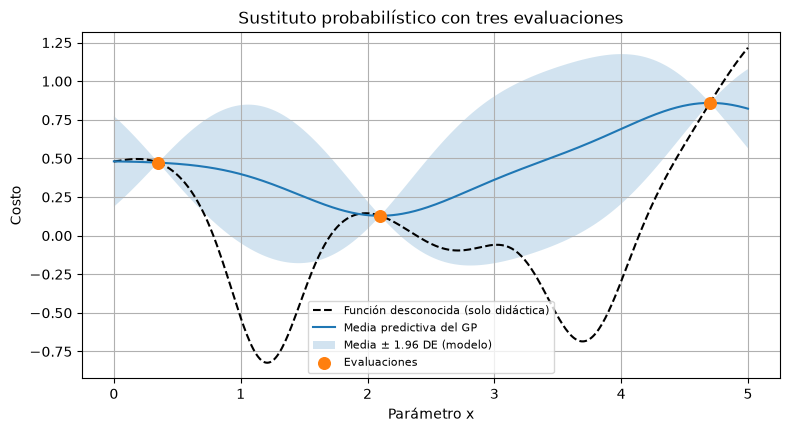

In [4]:
def objective_1d(x):
    x = np.asarray(x, dtype=float)
    return (0.12*(x-2.0)**2
            -0.75*np.exp(-((x-1.2)**2)/0.12)
            -1.15*np.exp(-((x-3.7)**2)/0.20)
            +0.15*np.sin(4*x))

X_grid = np.linspace(0, 5, 401).reshape(-1, 1)
X_obs = np.array([[0.35], [2.1], [4.7]])
y_obs = objective_1d(X_obs[:, 0])

def fit_gp(X, y, length_scale=0.65, noise_var=1e-7):
    # Hiperparámetros fijos: no se consume presupuesto adicional en evaluaciones reales.
    kernel = ConstantKernel(1.0, constant_value_bounds="fixed") * RBF(length_scale, length_scale_bounds="fixed")
    gp = GaussianProcessRegressor(kernel=kernel, alpha=noise_var,
                                  normalize_y=True, optimizer=None)
    gp.fit(np.asarray(X, dtype=float), np.asarray(y, dtype=float))
    return gp

gp = fit_gp(X_obs, y_obs)
mu, sd = gp.predict(X_grid, return_std=True)
fig, ax = plt.subplots()
ax.plot(X_grid[:, 0], objective_1d(X_grid[:, 0]), "k--", label="Función desconocida (solo didáctica)")
ax.plot(X_grid[:, 0], mu, label="Media predictiva del GP")
ax.fill_between(X_grid[:, 0], mu-1.96*sd, mu+1.96*sd, alpha=.2, label="Media ± 1.96 DE (modelo)")
ax.scatter(X_obs[:, 0], y_obs, marker="o", s=70, zorder=5, label="Evaluaciones")
ax.set(xlabel="Parámetro x", ylabel="Costo", title="Sustituto probabilístico con tres evaluaciones")
ax.legend(loc="best", fontsize=8)
plt.show()

### PAUSA DIDÁCTICA 4 — ¿De dónde salen la línea y la banda?

Con las tres posiciones observadas $X=(x_1,x_2,x_3)$ construimos la matriz $K$, donde cada entrada es $K_{ij}=k(x_i,x_j)$. También formamos el vector $k_*$ de covarianzas entre el punto nuevo $x_*$ y las tres posiciones medidas.

La **media posterior** combina los resultados observados con pesos determinados por esas covarianzas. La **varianza posterior** mide la incertidumbre que queda después de conocer las tres observaciones. Ambas salen de la fórmula de condicionamiento de una normal multivariada; no son curvas dibujadas a mano.

**Detalles del código original que debes reconocer:** `GaussianProcessRegressor` realiza esos cálculos; `RBF(length_scale=0.65)` fija la escala horizontal; `ConstantKernel(1.0)` fija la amplitud; `normalize_y=True` centra y reescala internamente los resultados; `alpha=1e-7` aporta una pequeña regularización/varianza de ruido; `optimizer=None` impide recalibrar automáticamente el kernel. Por eso el código no es exactamente el GP de media previa cero de nuestro ejemplo manual anterior.

### Vocabulario para leer la gráfica y el código

**Línea central:** predicción de la **media posterior** del GP, no la función verdadera. **Banda sombreada:** intervalo construido con la desviación estándar predictiva, por ejemplo $\mu(x)\pm1.96s(x)$ para una banda normal aproximada del 95 %. **Posterior** quiere decir «después de incorporar los datos»; **prior** o *a priori*, «antes de incorporarlos».

En el código, `fit(X_obs, y_obs)` usa las posiciones y resultados conocidos; `predict(X_grid, return_std=True)` devuelve, para cada posición de la malla, una media y una desviación estándar. `X_grid` es una colección de puntos para **dibujar predicciones**, no observaciones nuevas de la máquina. `length_scale` corresponde a $\ell$; `alpha` regulariza la matriz y se interpreta aquí como una pequeña varianza de ruido; `optimizer=None` deja fijos los parámetros elegidos del kernel. **Normalizar** los resultados significa reexpresarlos internamente en una escala centrada y estandarizada, no cambiar la función física.


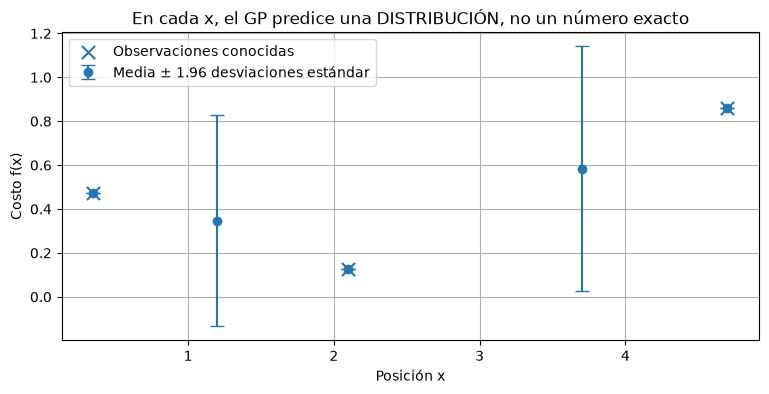

x=0.35: media=0.473; desviación estándar=0.000
x=1.20: media=0.348; desviación estándar=0.246
x=2.10: media=0.129; desviación estándar=0.000
x=3.70: media=0.584; desviación estándar=0.284
x=4.70: media=0.860; desviación estándar=0.000


In [5]:
# GRÁFICA DIDÁCTICA NUEVA: predicción en puntos específicos (no modifica el código original)
probe = np.array([[0.35], [1.2], [2.1], [3.7], [4.7]])
probe_mu, probe_sd = gp.predict(probe, return_std=True)
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(probe[:, 0], probe_mu, yerr=1.96*probe_sd, fmt="o", capsize=5,
            label="Media ± 1.96 desviaciones estándar")
ax.scatter(X_obs[:, 0], y_obs, marker="x", s=90, label="Observaciones conocidas")
ax.set(xlabel="Posición x", ylabel="Costo f(x)",
       title="En cada x, el GP predice una DISTRIBUCIÓN, no un número exacto")
ax.legend(); plt.show()
for x, m, s in zip(probe[:, 0], probe_mu, probe_sd):
    print(f"x={x:.2f}: media={m:.3f}; desviación estándar={s:.3f}")

## <span style="color:#bd232b">4.3 Discusión: qué representa la banda</span>

La banda representa incertidumbre **condicional al modelo GP especificado**. No es una garantía de cobertura frecuentista del 95 % para cualquier función desconocida. Cerca de observaciones sin ruido se contrae; lejos de ellas puede ampliarse. Examina también el efecto de cambiar la longitud de escala del núcleo.

### PAUSA DIDÁCTICA 5 — Saber no es decidir

El GP nos puede decir: «en $x=3.7$ espero un costo bajo, pero no estoy muy seguro». Esa predicción **todavía no es una orden de experimentar**. Necesitamos una regla que valore los candidatos.

Para **minimizar**, nuestro récord actual es el menor costo ya observado. **Expected Improvement (EI)** pregunta, para cada candidato: «si lo mido, ¿cuánto espero mejorar el récord?». Una región puede ser atractiva porque su media es baja (**explotación**) o porque, aun con media mediocre, existe una probabilidad de encontrar un costo extraordinariamente bajo (**exploración**).

**EI no es la probabilidad de mejorar.** Es el *tamaño promedio de la mejora positiva*, que incorpora tanto la probabilidad como la magnitud de la mejora. El algoritmo selecciona el $x$ con EI más alto. No selecciona automáticamente el punto con mayor incertidumbre.

# <span style="color:#174ea6">5. Adquisición: dónde evaluar después</span>

BO decide mediante una función $a_n(x)$. Para minimizar, sean $f_{\min}=\min_{i\le n} y_i$ y $Y(x)\sim\mathcal N(\mu_n(x),s_n^2(x))$.

**Expected Improvement (EI)**, con margen de exploración $\xi\ge 0$:

$$\mathrm{EI}(x)=\mathbb E\left[\max(f_{\min}-\xi-Y(x),0)\right].$$

Si $s_n(x)>0$ y $z=(f_{\min}-\xi-\mu_n(x))/s_n(x)$,

$$\mathrm{EI}(x)=(f_{\min}-\xi-\mu_n(x))\Phi(z)+s_n(x)\phi(z).$$

Si $s_n(x)=0$, se utiliza $\max(f_{\min}-\xi-\mu_n(x),0)$. EI equilibra predicciones prometedoras e incertidumbre. **Precaución:** si las observaciones son ruidosas, el mejor $y_i$ no necesariamente es la mejor función latente; este EI introductorio es adecuado para evaluaciones prácticamente deterministas o promedios con ruido pequeño.

**Lower Confidence Bound (LCB)** para minimizar:

$$\mathrm{LCB}(x)=\mu_n(x)-\kappa s_n(x),\qquad x_{n+1}=\arg\min_x\mathrm{LCB}(x).$$

Se suele hablar de *UCB* cuando se **maximiza** una utilidad. Para nuestro costo a minimizar corresponde LCB, o equivalentemente UCB aplicado a $-f$. Aumentar $\kappa$ favorece regiones inciertas.


## <span style="color:#bd232b">5.1 ¿Cómo decide la optimización bayesiana dónde realizar el siguiente experimento?</span>
Hasta ahora hemos construido un modelo probabilístico de nuestra función desconocida mediante un **proceso gaussiano**. Este modelo nos proporciona dos resultados para cualquier punto $x$:

- **Una predicción:** cuánto creemos que vale la función en ese punto.
- **Una incertidumbre:** qué tan seguros estamos de esa predicción.

Pero todavía nos falta resolver una pregunta fundamental:

**Si podemos realizar un solo experimento adicional, ¿en qué punto deberíamos hacerlo?**

Para responderla utilizamos una *función de adquisición*.

### 5.2.1. El problema: elegir entre lo prometedor y lo desconocido

Imaginemos que estamos tratando de minimizar el costo de un proceso industrial.

Hemos realizado varios experimentos y el menor costo encontrado hasta ahora es de **5 unidades monetarias**.

Nuestro proceso gaussiano propone tres posibles puntos para el siguiente experimento:

| Candidato | Costo predicho | Incertidumbre |
|---|---:|---:|
| A | 4 | 0,5 |
| B | 5 | 2,0 |
| C | 7 | 0,5 |

El candidato A parece atractivo porque predice un costo inferior a 5.

El candidato B parece menos atractivo, pero tiene una incertidumbre considerable. Aunque su costo predicho sea 5, el costo verdadero podría ser mucho menor.

El candidato C parece poco prometedor: su costo predicho es alto y la incertidumbre es pequeña.

Aquí aparecen dos estrategias:

- **Explotación (*exploitation*):** experimentar donde el modelo ya predice buenos resultados.
- **Exploración (*exploration*):** experimentar donde existe incertidumbre y podríamos descubrir resultados inesperadamente buenos.

La optimización bayesiana intenta equilibrar ambas estrategias.

### 5.2.2. ¿Qué es una función de adquisición?

Una función de adquisición es una regla matemática que asigna una puntuación a cada posible punto de evaluación.

La representamos como:

$$
a_n(x)
$$

Donde:

- $a$: función de adquisición.
- $x$: punto candidato para el siguiente experimento.
- $n$: número de experimentos realizados hasta el momento.

**Importante:** la función de adquisición no es la función objetivo que queremos minimizar. Es una función auxiliar, generalmente barata de calcular, que nos ayuda a decidir dónde evaluar la función objetivo.

Estudiaremos dos funciones de adquisición: **Expected Improvement (EI)** y **Lower Confidence Bound (LCB)**.

### 5.2.3. Antes de continuar: ¿qué sabemos de cada candidato?

Nuestro proceso gaussiano proporciona una distribución normal predictiva:

$$
\boxed{
Y(x)\sim\mathcal N(\mu_n(x),s_n^2(x))
}
$$

Esta expresión significa que el valor desconocido de la función en el punto $x$ se representa mediante una distribución normal.

Sus componentes son:

- $Y(x)$: variable aleatoria que representa el valor desconocido de la función.
- $\mathcal N$: distribución normal.
- $\mu_n(x)$: media predictiva; nuestro mejor pronóstico del valor de la función.
- $s_n(x)$: desviación estándar predictiva; medida de incertidumbre.
- $s_n^2(x)$: varianza predictiva.
- $n$: cantidad de observaciones utilizadas para construir la predicción.

Por ejemplo:

$$
Y(B)\sim\mathcal N(5,2^2)
$$

Significa que para el candidato B predecimos un costo de 5, con desviación estándar de 2.

No estamos afirmando que el costo verdadero cambie cada vez que lo evaluamos. Estamos representando probabilísticamente nuestro desconocimiento de ese costo.

### 5.2.4. Expected Improvement (EI): ¿cuánto esperamos mejorar?

*Expected Improvement* significa **mejora esperada**.

Su idea es sencilla: queremos elegir el punto donde esperamos conseguir la mayor reducción del costo respecto al mejor resultado encontrado hasta ahora.

Primero definimos:

$$
\boxed{
f_{\min}=\min_{i\le n}y_i
}
$$

Donde:

- $f_{\min}$: menor costo observado hasta el momento.
- $y_i$: costo obtenido en el experimento número $i$.
- $\min$: operación que selecciona el menor valor.
- $i\le n$: consideramos todos los experimentos realizados.

En nuestro ejemplo:

$$
f_{\min}=5
$$

Ahora supongamos que realizamos otro experimento:

| Nuevo costo | ¿Cuánto mejoramos? |
|---|---:|
| 2 | 3 unidades |
| 4 | 1 unidad |
| 5 | 0 unidades |
| 7 | 0 unidades |

Cuando el nuevo costo es mayor que 5, la mejora es cero. No consideramos mejoras negativas.

Matemáticamente:

$$
I(x)=\max(f_{\min}-Y(x),0)
$$

Aquí, $\max$ significa seleccionar el mayor de los dos valores.

Pero existe un problema: todavía no conocemos $Y(x)$, porque aún no hemos realizado el experimento.

Por eso calculamos su **mejora esperada**:

$$
\boxed{
\mathrm{EI}(x)=
\mathbb E[\max(f_{\min}-Y(x),0)]
}
$$

El símbolo $\mathbb E$ representa la esperanza matemática.

En palabras:

**Consideramos todos los resultados que podrían obtenerse, calculamos cuánto mejoraríamos con cada uno y obtenemos el promedio ponderado por sus probabilidades.**

#### Introducción de un margen de mejora

Podemos exigir que el nuevo resultado supere al mejor actual por una cantidad mínima $\xi$.

La expresión general es:

$$
\boxed{
\mathrm{EI}(x)=
\mathbb E[\max(f_{\min}-\xi-Y(x),0)]
}
$$

Donde $\xi\ge0$ es un parámetro elegido por el investigador.

Por ejemplo, si $f_{\min}=5$ y $\xi=0,5$, solo contabilizamos una mejora positiva cuando el nuevo costo es inferior a 4,5.

Cuando $\xi=0$, cualquier reducción del costo cuenta como mejora.

#### ¿Cómo se calcula EI?

Como $Y(x)$ tiene una distribución normal, podemos obtener una fórmula explícita:

$$
\boxed{
\mathrm{EI}(x)=
(f_{\min}-\xi-\mu_n(x))\Phi(z)
+s_n(x)\phi(z)
}
$$

Donde:

$$
\boxed{
z=\frac{f_{\min}-\xi-\mu_n(x)}{s_n(x)}
}
$$

Esta expresión se utiliza cuando $s_n(x)>0$.

Definamos los símbolos nuevos:

- $z$: distancia entre el umbral de mejora y la media predictiva, medida en desviaciones estándar.
- $\Phi(z)$: función de distribución acumulada de la normal estándar. En este caso, representa la probabilidad de superar el umbral de mejora.
- $\phi(z)$: función de densidad de la normal estándar evaluada en $z$.
- $\xi$: margen de mejora exigido.

La fórmula contiene dos términos que, conjuntamente, incorporan la calidad de la predicción y su incertidumbre.

No es necesario memorizar la fórmula en esta primera aproximación. Lo importante es comprender que **EI combina cuánto podríamos mejorar con la probabilidad de conseguir esa mejora**.

Si la desviación estándar es cero, no existe incertidumbre predictiva en el punto y utilizamos:

$$
\mathrm{EI}(x)=
\max(f_{\min}-\xi-\mu_n(x),0)
$$

---
### Nota metodológica. ¿De dónde surge la fórmula de Expected Improvement (EI)?

La función de adquisición *Expected Improvement* (EI), o **mejora esperada**, surge de una idea sencilla: elegir el próximo experimento considerando cuánto podríamos mejorar respecto al mejor resultado obtenido hasta el momento.

No se trata de una fórmula arbitraria. Es la consecuencia de definir qué entendemos por mejora y calcular su esperanza matemática utilizando la distribución predictiva del proceso gaussiano.

**1. Definimos qué significa mejorar**

Supongamos que estamos minimizando una función de costo y que el menor valor observado hasta ahora es:

$$
f_{\min}=5
$$

Si un nuevo experimento produce un costo de 3, habremos mejorado en 2 unidades. Si produce un costo de 7, no habremos conseguido ninguna mejora.

Por tanto, definimos la mejora como:

$$
I(x)=\max(f_{\min}-Y(x),0)
$$

Donde:

- $I(x)$: mejora que obtendríamos al evaluar el punto $x$.
- $f_{\min}$: menor costo observado hasta ahora.
- $Y(x)$: variable aleatoria que representa el resultado todavía desconocido del experimento.
- $\max(a,b)$: operación que selecciona el mayor de dos valores.

Los costos 3 y 7 son ejemplos hipotéticos, no resultados de experimentos adicionales.

**2. Calculamos la mejora esperada**

Como todavía no hemos realizado el experimento, desconocemos el valor de $Y(x)$. Sin embargo, nuestro proceso gaussiano proporciona una distribución predictiva:

$$
Y(x)\sim\mathcal N(\mu_n(x),s_n^2(x))
$$

La media $\mu_n(x)$ representa el costo predicho y la desviación estándar $s_n(x)$ representa nuestra incertidumbre.

Podemos entonces considerar todos los resultados posibles, calcular la mejora correspondiente a cada uno y obtener su promedio ponderado por las probabilidades.

Esto conduce directamente a:

$$
\boxed{
\mathrm{EI}(x)=
\mathbb E[\max(f_{\min}-Y(x),0)]
}
$$

El símbolo $\mathbb E$ representa la esperanza matemática.

**Esta es la idea original de EI: calcular cuánto esperamos mejorar antes de realizar el experimento.**

**3. Introducimos un margen de mejora**

Podemos incorporar un parámetro $\xi\geq0$, que establece un margen adicional de mejora:

$$
\boxed{
\mathrm{EI}(x)=
\mathbb E[\max(f_{\min}-\xi-Y(x),0)]
}
$$

Definimos el umbral:

$$
T=f_{\min}-\xi
$$

Por ejemplo, si $f_{\min}=5$ y $\xi=0,5$, solo contabilizamos mejoras positivas cuando el nuevo costo es inferior a 4,5.

**4. ¿De dónde aparecen las funciones $\Phi$ y $\phi$?**

La esperanza matemática anterior puede expresarse mediante una integral:

$$
\mathrm{EI}(x)=
\int_{-\infty}^{T}(T-y)p_n(y\mid x)\,dy
$$

Aquí:

- $y$: un posible valor del costo.
- $p_n(y\mid x)$: densidad de probabilidad predictiva del costo en el punto $x$, después de $n$ observaciones.
- $\int$: operación de integración, que permite calcular el promedio ponderado sobre todos los resultados posibles.
- $T-y$: mejora obtenida cuando el costo $y$ es inferior al umbral $T$.

El límite superior de integración es $T$ porque los costos mayores o iguales a ese umbral no producen una mejora positiva.

Como la distribución predictiva es normal, podemos resolver analíticamente la integral.

Para ello, estandarizamos la variable mediante:

$$
z=\frac{T-\mu_n(x)}{s_n(x)}
$$

Cuando $s_n(x)>0$, el resultado es:

$$
\boxed{
\mathrm{EI}(x)=
(T-\mu_n(x))\Phi(z)+s_n(x)\phi(z)
}
$$

Donde:

- $\Phi(z)$: función de distribución acumulada de la normal estándar. En este contexto, representa la probabilidad de obtener un costo inferior al umbral $T$.
- $\phi(z)$: función de densidad de la normal estándar, evaluada en $z$.
- $z$: distancia entre el umbral y la media predictiva, expresada en unidades de desviación estándar.

Por tanto, las funciones $\Phi$ y $\phi$ aparecen como consecuencia matemática de integrar la mejora bajo una distribución normal. **No son supuestos adicionales introducidos para construir EI.**

Si $s_n(x)=0$, la mejora esperada se calcula directamente como $\max(T-\mu_n(x),0)$.

**5. Interpretación para la optimización bayesiana**

La fórmula permite que un candidato resulte atractivo por dos razones:

- Su costo medio predicho es suficientemente bajo para ofrecer una mejora.
- Su incertidumbre es suficientemente grande para que exista la posibilidad de descubrir un costo mucho menor que el esperado.

Así, EI combina naturalmente la **explotación** de regiones prometedoras y la **exploración** de regiones inciertas.

La regla de selección es:

$$
\boxed{
x_{n+1}=\arg\max_x\mathrm{EI}(x)
}
$$

Es decir, seleccionamos como siguiente experimento el punto que presenta la mayor mejora esperada.

**Idea fundamental:** primero definimos qué significa mejorar; después calculamos el promedio probabilístico de esa mejora. La expresión matemática de EI surge de resolver ese promedio bajo la distribución normal predictiva proporcionada por el proceso gaussiano.


---

#### Un ejemplo numérico

Con $f_{\min}=5$ y $\xi=0$:

| Candidato | Media predictiva | Desviación estándar | EI aproximado |
|---|---:|---:|---:|
| A | 4 | 0,5 | 1,004 |
| B | 5 | 2,0 | 0,798 |
| C | 7 | 0,5 | 0,000004 |

EI seleccionaría el candidato A, porque presenta la mayor mejora esperada.

Sin embargo, observa que B también tiene una mejora esperada importante, aunque su costo medio predicho sea igual al mejor costo actual. Esto ocurre porque su incertidumbre permite que existan resultados considerablemente mejores.

**La regla de decisión de EI es:**

$$
\boxed{
x_{n+1}=\arg\max_x\mathrm{EI}(x)
}
$$

El símbolo $\arg\max$ significa encontrar el valor de $x$ donde la función alcanza su máximo.

### 5.2.5. Lower Confidence Bound (LCB): una alternativa más sencilla

*Lower Confidence Bound* significa **límite inferior de confianza**.

Para minimizar una función, utilizamos:

$$
\boxed{
\mathrm{LCB}(x)=\mu_n(x)-\kappa s_n(x)
}
$$

Donde:

- $\mathrm{LCB}(x)$: puntuación del candidato $x$.
- $\mu_n(x)$: costo medio predicho.
- $s_n(x)$: desviación estándar predictiva.
- $\kappa\ge0$: parámetro que controla cuánto favorecemos la incertidumbre.

La fórmula es muy sencilla:

**Tomamos el costo predicho y le restamos una cantidad proporcional a la incertidumbre.**

¿Por qué restamos?

Porque estamos minimizando. Si existe mucha incertidumbre, el costo verdadero podría ser considerablemente menor que el costo predicho.

Con $\kappa=1$:

| Candidato | Media | Incertidumbre | LCB |
|---|---:|---:|---:|
| A | 4 | 0,5 | 3,5 |
| B | 5 | 2,0 | 3,0 |
| C | 7 | 0,5 | 6,5 |

En este caso LCB selecciona B, porque tiene la menor puntuación.

La regla es:

$$
\boxed{
x_{n+1}=\arg\min_x\mathrm{LCB}(x)
}
$$

El símbolo $\arg\min$ significa encontrar el valor de $x$ que minimiza la expresión.

#### ¿Qué sucede cuando cambiamos $\kappa$?

Si $\kappa=0$:

$$
\mathrm{LCB}(x)=\mu_n(x)
$$

Solo importa el costo predicho. Estamos favoreciendo la explotación.

Si aumentamos $\kappa$, los puntos con mayor incertidumbre reciben puntuaciones más bajas y se vuelven más atractivos.

Por tanto:

- $\kappa$ pequeño: mayor importancia de la predicción.
- $\kappa$ grande: mayor importancia de la incertidumbre.

El valor de $\kappa$ es una decisión de modelado. No representa automáticamente un nivel de confianza estadística determinado.

### 5.2.6. Interpretación gráfica: ¿qué está haciendo la optimización bayesiana?

La siguiente figura ilustra la relación entre la predicción del proceso gaussiano, su incertidumbre y la selección del siguiente punto experimental.

<img src="../Imagenes/optimizacion_gaussian.svg" width="800"/>

*Figura 105A.1 Interpretación gráfica de la optimización bayesiana.*

Para interpretar la figura, debemos distinguir tres elementos:

1. **La curva de predicción:** representa la media posterior $\mu_n(x)$, es decir, el valor que esperamos obtener en cada punto.
2. **La incertidumbre:** indica dónde conocemos mejor la función y dónde todavía tenemos dudas. Habitualmente se representa mediante una banda alrededor de la media.
3. **La función de adquisición:** utiliza las predicciones y sus incertidumbres para identificar el siguiente punto que conviene evaluar.

El siguiente experimento no tiene que realizarse necesariamente donde la media predictiva es menor.

Podemos preferir una región más incierta si existe suficiente posibilidad de encontrar allí un resultado mejor.

Esta es la característica que distingue a la optimización bayesiana de una búsqueda basada exclusivamente en las predicciones del modelo.

### 5.2.7. ¿Cuál de las dos funciones debemos utilizar?

EI y LCB persiguen el mismo objetivo general: seleccionar experimentos que permitan encontrar un buen mínimo utilizando pocas evaluaciones.

Sin embargo, emplean criterios diferentes.

| Característica | EI | LCB |
|---|---|---|
| Pregunta principal | ¿Cuánto esperamos mejorar? | ¿Qué punto presenta un límite inferior más prometedor? |
| Media predictiva | Sí | Sí |
| Incertidumbre | Sí | Sí |
| Parámetro | $\xi$ | $\kappa$ |
| Selección | Maximizar EI | Minimizar LCB |

Ninguna de las dos funciones es universalmente superior. Su comportamiento depende de la función objetivo, del kernel, de las observaciones y de los parámetros utilizados.

### 5.2.8. ¿Qué ocurre después de seleccionar el punto?

Supongamos que EI seleccionó el candidato A.

Entonces:

1. Ejecutamos realmente el experimento en A.
2. Observamos el costo verdadero obtenido.
3. Agregamos el nuevo par $(x_{n+1},y_{n+1})$ a nuestros datos.
4. Actualizamos el proceso gaussiano.
5. Calculamos nuevamente la función de adquisición.
6. Seleccionamos el siguiente experimento.

Este procedimiento se repite hasta agotar el presupuesto disponible o satisfacer algún criterio de parada.

**Idea fundamental de esta sección**

El proceso gaussiano nos dice **qué esperamos y qué tan inciertos estamos**.

La función de adquisición nos dice **dónde conviene experimentar a continuación**.

EI busca la mayor mejora esperada. LCB favorece predicciones bajas y regiones inciertas.

En ambos casos, la optimización bayesiana intenta aprender lo suficiente sobre la función desconocida para encontrar su mínimo con el menor número posible de experimentos.

*Nota metodológica:* las fórmulas de EI presentadas corresponden a una introducción con observaciones exactas o prácticamente deterministas. Cuando existe ruido de medición apreciable, el menor valor observado no necesariamente representa el menor valor de la función latente y pueden requerirse variantes de la función de adquisición que modelen explícitamente ese ruido.

### Diccionario inmediato de las funciones de adquisición

**Para esta sección minimizamos costos:** cuanto menor sea $f(x)$, mejor. **$f_{\min}$** es el menor costo **observado** hasta ahora; no necesariamente el mínimo verdadero de toda la función. **$\min_{i\le n}y_i$** busca el menor resultado entre los primeros $n$ experimentos. **$Y(x)$** (mayúscula) es la variable aleatoria que representa lo que podría valer la función en un punto aún no evaluado; **$\mathcal N(\mu,s^2)$** indica distribución normal con media $\mu$ y varianza $s^2$.

- **EI (*Expected Improvement*)**: *mejora esperada*. Calcula el promedio probabilístico de cuánto superaríamos el récord si probáramos $x$.
- **$\mathbb E[\cdot]$**: esperanza matemática o promedio ponderado por probabilidades.
- **$\max(a,0)$**: toma $a$ si es positivo y cero si es negativo; por eso no contabilizamos como «mejora» un resultado peor que el récord.
- **$\xi$** (xi): margen exigido para considerar una mejora; en la fórmula se resta del récord. Si $\xi=0$, basta con mejorar el récord; un $\xi$ positivo exige superarlo por más.
- **$z$**: distancia entre el umbral de mejora y la media predictiva, medida en unidades de desviación estándar. Es una *puntuación tipificada*.
- **$\Phi(z)$** (fi mayúscula): probabilidad acumulada de la normal estándar hasta $z$; **$\phi(z)$** (fi minúscula): altura de su función de densidad en $z$. No son lo mismo.
- **$s_n(x)>0$**: existe incertidumbre predictiva positiva; si $s_n(x)=0$, la predicción es puntual y usamos el caso separado.
- **LCB (*Lower Confidence Bound*)**: *cota inferior de confianza*, aquí un puntaje de selección $\mu_n(x)-\kappa s_n(x)$; no es por sí mismo una garantía estadística de cobertura.
- **$\kappa$** (kappa): coeficiente no negativo que determina cuánto premiamos la incertidumbre. Con mayor $\kappa$, la cota inferior baja más en puntos inciertos.
- **UCB (*Upper Confidence Bound*)**: cota superior, habitualmente usada para **maximizar**. No debe confundirse con LCB en minimización.

**Diferencia clave:** EI se **maximiza** porque un número mayor significa más mejora esperada; LCB se **minimiza** porque buscamos una cota baja de costo. Una «función de adquisición» no evalúa la máquina: evalúa el **interés de hacer una consulta**.


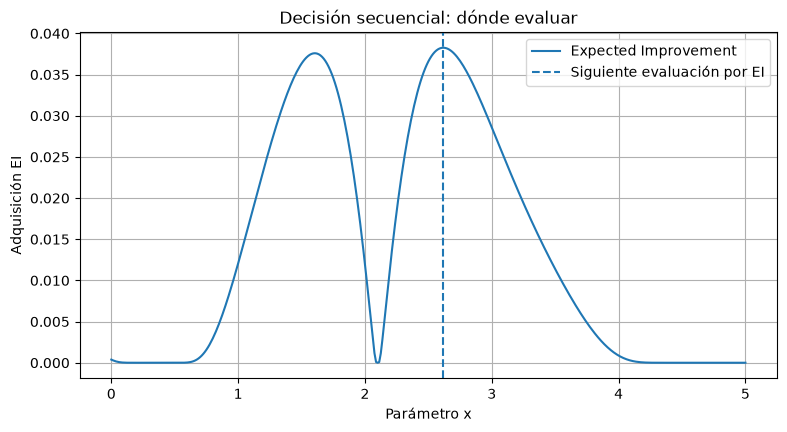

EI elige x=2.613; LCB elige x=2.713


In [3]:
def expected_improvement(mu, sd, best, xi=0.01):
    mu, sd = np.asarray(mu), np.asarray(sd)
    improvement = best - xi - mu
    out = np.zeros_like(mu, dtype=float)
    mask = sd > 1e-12
    z = improvement[mask] / sd[mask]
    out[mask] = improvement[mask] * norm.cdf(z) + sd[mask] * norm.pdf(z)
    out[~mask] = np.maximum(improvement[~mask], 0.0)
    return np.maximum(out, 0.0)

EI = expected_improvement(mu, sd, best=np.min(y_obs), xi=0.01)
LCB = mu - 1.5*sd
next_ei = int(np.argmax(EI))
next_lcb = int(np.argmin(LCB))
fig, ax = plt.subplots()
ax.plot(X_grid[:, 0], EI, label="Expected Improvement")
ax.axvline(X_grid[next_ei, 0], linestyle="--", label="Siguiente evaluación por EI")
ax.set(xlabel="Parámetro x", ylabel="Adquisición EI", title="Decisión secuencial: dónde evaluar")
ax.legend()
plt.show()
print(f"EI elige x={X_grid[next_ei,0]:.3f}; LCB elige x={X_grid[next_lcb,0]:.3f}")
assert np.all(EI >= -1e-12)

### PAUSA DIDÁCTICA 6 — Lo que debes mirar en el ciclo

1. **Antes de medir:** el GP predice media e incertidumbre en toda la malla.
2. **Decisión:** EI asigna una puntuación a cada posición y elige la mayor.
3. **Experimento:** consultamos la función verdadera **solo en el punto elegido**.
4. **Actualización:** agregamos el nuevo par $(x,f(x))$ y volvemos a ajustar el GP.
5. **Resultado acumulado:** el mejor costo observado solo puede mejorar o permanecer igual.

La gráfica de la izquierda del siguiente bloque muestra **dónde se gastaron las evaluaciones**; la de la derecha, **cuánto mejoró el récord**. Encontrar una buena solución no significa haber reconstruido perfectamente toda la función.

# <span style="color:#174ea6">6. Laboratorio 1: ciclo completo de BO</span>

Partimos de las mismas tres observaciones. En cada iteración: ajustamos el GP, calculamos EI, seleccionamos un candidato no evaluado, consultamos la función y actualizamos los datos. El conjunto de candidatos es una discretización: el máximo encontrado de EI es el máximo **sobre esa malla**, no necesariamente sobre el dominio continuo.

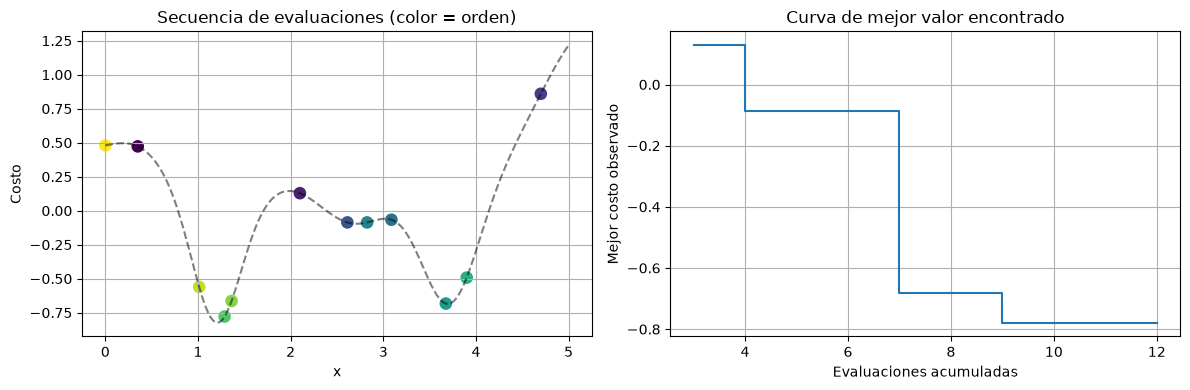

Nuevas evaluaciones: [2.613 3.088 2.825 3.675 3.9   1.288 1.362 1.012 0.   ]
Mejor costo observado: -0.7786


In [4]:
def sequential_bo_1d(n_extra=9):
    X = X_obs.copy()
    y = y_obs.copy()
    selected = []
    history = [float(np.min(y))]
    for step in range(n_extra):
        model = fit_gp(X, y)
        mean, std = model.predict(X_grid, return_std=True)
        acq = expected_improvement(mean, std, np.min(y))
        # Impedir reevaluar el mismo punto de la malla.
        available = np.min(np.abs(X_grid - X.reshape(1, -1)), axis=1) > 1e-9
        acq[~available] = -np.inf
        j = int(np.argmax(acq))
        x_new = X_grid[j:j+1]
        y_new = objective_1d(x_new[:, 0])
        X = np.vstack([X, x_new])
        y = np.r_[y, y_new]
        selected.append(float(x_new[0, 0]))
        history.append(float(np.min(y)))
    return X, y, selected, np.asarray(history)

X_final, y_final, sequence, best_history = sequential_bo_1d()
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(X_grid[:,0], objective_1d(X_grid[:,0]), "k--", alpha=.5)
axs[0].scatter(X_final[:,0], y_final, c=np.arange(len(y_final)), cmap="viridis", s=65)
axs[0].set(xlabel="x", ylabel="Costo", title="Secuencia de evaluaciones (color = orden)")
axs[1].step(np.arange(len(best_history))+len(y_obs), best_history, where="post")
axs[1].set(xlabel="Evaluaciones acumuladas", ylabel="Mejor costo observado", title="Curva de mejor valor encontrado")
plt.tight_layout(); plt.show()
print("Nuevas evaluaciones:", np.round(sequence, 3))
print("Mejor costo observado:", round(float(np.min(y_final)), 4))
assert len(y_final) == len(y_obs) + 9
assert np.all(np.diff(best_history) <= 1e-12)

### PAUSA DIDÁCTICA 7 — ¿Por qué comparar con búsqueda aleatoria?

Un solo recorrido puede favorecer por casualidad a cualquiera de los métodos. Por eso el cuaderno repite el experimento con **igual presupuesto**, compara resultados **pareados por escenario** y presenta variabilidad. Esta parte ya no explica qué es un GP: examina si elegir adaptativamente los experimentos aporta una ventaja medible.

Para una primera lectura, puedes detenerte al terminar la sección 5. Las secciones 6–9 son la continuación experimental y aplicada; no hace falta entenderlas para captar la esencia de BO.

# <span style="color:#174ea6">7. Laboratorio 2: comparación pareada con presupuesto idéntico</span>

Para comparar BO con búsqueda aleatoria necesitamos **más de una repetición** y exactamente el mismo número de evaluaciones por repetición. Usaremos un problema sintético bidimensional que imita el ajuste de dos parámetros de control, **sin afirmar que reproduce la física de Hydro-Lab**.

El experimento controla:

- **Dominio:** $[0,1]^2$.
- **Inicialización pareada:** los mismos $n_0$ puntos para BO y búsqueda aleatoria en cada réplica.
- **Presupuesto:** $B$ evaluaciones totales, contando las iniciales.
- **Escenario de entrenamiento:** misma función de costo para ambos métodos dentro de cada réplica.
- **Semillas independientes:** distintas réplicas permiten examinar variabilidad; los escenarios de prueba se reservan para evaluar generalización.

No se asume de antemano que BO ganará. En problemas de baja dimensión y funciones suaves suele aprovechar mejor el presupuesto; un GP mal especificado puede perder frente a una búsqueda aleatoria razonable.

### Diccionario del experimento comparativo

- **$[0,1]^2$**: conjunto de pares $(x_1,x_2)$ con ambos componentes entre 0 y 1. El superíndice 2 indica **dos dimensiones**, no elevar un número al cuadrado.
- **$n_0$**: número de puntos iniciales compartidos por ambos métodos.
- **$B$**: presupuesto máximo de evaluaciones por réplica, **incluyendo** las $n_0$ iniciales.
- **Réplica**: ejecución completa e independiente del experimento comparativo, normalmente con una semilla distinta.
- **Semilla aleatoria**: número que fija el estado inicial del generador pseudoaleatorio, permitiendo reproducir el mismo sorteo.
- **Comparación pareada**: BO y búsqueda aleatoria se prueban bajo condiciones iniciales y escenarios comparables en una misma réplica; se comparan sus diferencias dentro de cada pareja.
- **Generalización / fuera de muestra**: desempeño en escenarios que **no se utilizaron** para elegir la configuración.
- **Búsqueda aleatoria**: propone puntos sin utilizar un modelo de la función para decidir dónde consultar.


## <span style="color:#bd232b">7.1 Función de costo sintética y protocolo</span>

In [5]:
def synthetic_control_cost(X, scenario=0):
    """Costo sintético, no API ni resultado de Hydro-Lab. X: (n, 2)."""
    X = np.atleast_2d(np.asarray(X, dtype=float))
    x, y = X[:,0], X[:,1]
    # El escenario desplaza ligeramente la región óptima.
    shift = 0.035*np.sin(0.8*scenario)
    return (0.60*(x-0.72-shift)**2 + 0.85*(y-0.30+shift)**2
            -0.25*np.exp(-((x-0.23)**2+(y-0.78)**2)/0.025)
            +0.07*np.sin(9*x)*np.cos(8*y)
            +0.10*np.maximum(0, x+y-1.3)**2)

GRID2 = np.array([(a,b) for a in np.linspace(0,1,19)
                         for b in np.linspace(0,1,19)], dtype=float)

def bo_vs_random(rep_seed, n_initial=4, budget=15):
    assert budget > n_initial
    local_rng = np.random.default_rng(rep_seed)
    scenario = int(rep_seed)
    initial_idx = local_rng.choice(len(GRID2), size=n_initial, replace=False)
    # La aleatoriedad del método aleatorio se fija antes de correr BO.
    remaining_idx = np.setdiff1d(np.arange(len(GRID2)), initial_idx)
    random_order = local_rng.permutation(remaining_idx)[:budget-n_initial]
    X_bo = GRID2[initial_idx].copy()
    y_bo = synthetic_control_cost(X_bo, scenario)
    X_rand = GRID2[np.r_[initial_idx, random_order]]
    y_rand = synthetic_control_cost(X_rand, scenario)
    best_bo = [float(np.min(y_bo))]
    for step in range(budget-n_initial):
        gp = fit_gp(X_bo, y_bo, length_scale=0.22)
        mu, sd = gp.predict(GRID2, return_std=True)
        ei = expected_improvement(mu, sd, float(np.min(y_bo)), xi=0.003)
        used = np.any(np.all(np.isclose(GRID2[:,None,:], X_bo[None,:,:], atol=1e-12), axis=2), axis=1)
        ei[used] = -np.inf
        ix = int(np.argmax(ei))
        new = GRID2[ix:ix+1]
        X_bo = np.vstack([X_bo, new])
        y_bo = np.r_[y_bo, synthetic_control_cost(new, scenario)]
        best_bo.append(float(np.min(y_bo)))
    best_rand = np.minimum.accumulate(y_rand)[n_initial-1:]
    return {"bo": np.asarray(best_bo), "random": best_rand,
            "X_bo": X_bo, "y_bo": y_bo, "X_random": X_rand,
            "y_random": y_rand, "scenario": scenario}

BUDGET = 15
REPLICAS = [11, 23, 37, 49, 61, 73]
results = [bo_vs_random(s, budget=BUDGET) for s in REPLICAS]
bo_curves = np.stack([r["bo"] for r in results])
rand_curves = np.stack([r["random"] for r in results])
assert bo_curves.shape == rand_curves.shape == (len(REPLICAS), BUDGET-4+1)
print("Réplicas:", len(REPLICAS), "· Presupuesto por método:", BUDGET, "evaluaciones")

Réplicas: 6 · Presupuesto por método: 15 evaluaciones


## <span style="color:#bd232b">7.2 Curvas, diferencias pareadas y variabilidad</span>

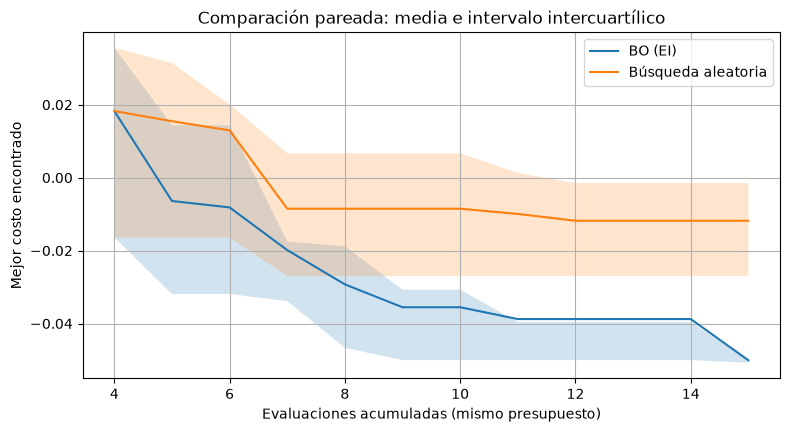

Diferencias finales (BO - aleatoria): [-0.0531 -0.0353 -0.0117 -0.0781 -0.03   -0.0214]
Media pareada: -0.0383
Mediana pareada: -0.0326
Réplicas en que BO obtiene menor costo: 6 / 6


In [6]:
evaluations = np.arange(4, BUDGET+1)
fig, ax = plt.subplots()
for curves, name in [(bo_curves, "BO (EI)"), (rand_curves, "Búsqueda aleatoria")]:
    ax.plot(evaluations, np.mean(curves, axis=0), label=name)
    ax.fill_between(evaluations, np.quantile(curves,.25,axis=0),
                    np.quantile(curves,.75,axis=0), alpha=.2)
ax.set(xlabel="Evaluaciones acumuladas (mismo presupuesto)",
       ylabel="Mejor costo encontrado", title="Comparación pareada: media e intervalo intercuartílico")
ax.legend(); plt.show()

paired_difference = bo_curves[:,-1] - rand_curves[:,-1]  # negativo favorece BO
print("Diferencias finales (BO - aleatoria):", np.round(paired_difference,4))
print("Media pareada:", round(float(np.mean(paired_difference)),4))
print("Mediana pareada:", round(float(np.median(paired_difference)),4))
print("Réplicas en que BO obtiene menor costo:", int(np.sum(paired_difference < 0)), "/", len(REPLICAS))
assert all(np.all(np.diff(curve) <= 1e-12) for curve in bo_curves)
assert all(np.all(np.diff(curve) <= 1e-12) for curve in rand_curves)

## <span style="color:#bd232b">7.3 Evaluación fuera del escenario de selección</span>

Seleccionar una configuración por desempeño en los escenarios de ajuste y después evaluarla **en los mismos escenarios** produce una estimación optimista de su calidad. En un laboratorio industrial se deben separar escenarios de selección y de prueba. El siguiente ejercicio usa escenarios de prueba que no intervienen en la selección de parámetros. Se evalúan **las configuraciones ganadoras**, no el método BO como si hubiera aprendido una política RL.

La métrica de prueba se reporta aparte del presupuesto de optimización: no se utiliza para elegir nuevos puntos ni alterar hiperparámetros.

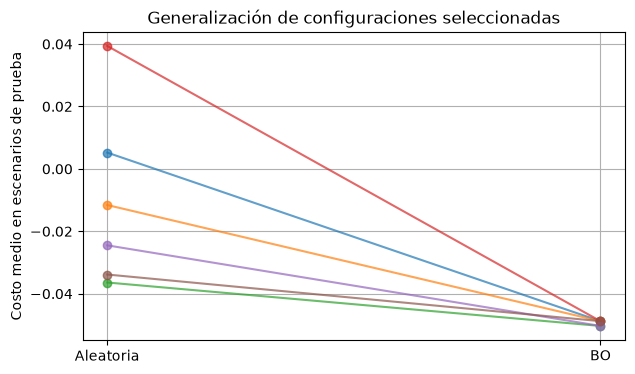

Diferencia media pareada en prueba (BO - aleatoria): -0.039


In [7]:
TEST_SCENARIOS = [101, 102, 103, 104, 105, 106, 107, 108]
test_bo, test_rand = [], []
for result in results:
    x_bo = result["X_bo"][np.argmin(result["y_bo"]):np.argmin(result["y_bo"])+1]
    x_r = result["X_random"][np.argmin(result["y_random"]):np.argmin(result["y_random"])+1]
    test_bo.append(np.mean([synthetic_control_cost(x_bo, s)[0] for s in TEST_SCENARIOS]))
    test_rand.append(np.mean([synthetic_control_cost(x_r, s)[0] for s in TEST_SCENARIOS]))
test_bo, test_rand = np.asarray(test_bo), np.asarray(test_rand)
fig, ax = plt.subplots(figsize=(7,4))
for j in range(len(REPLICAS)):
    ax.plot([0,1],[test_rand[j],test_bo[j]], marker="o", alpha=.7)
ax.set(xticks=[0,1], xticklabels=["Aleatoria", "BO"], ylabel="Costo medio en escenarios de prueba",
       title="Generalización de configuraciones seleccionadas")
plt.show()
print("Diferencia media pareada en prueba (BO - aleatoria):", round(float(np.mean(test_bo-test_rand)),4))

# <span style="color:#174ea6">8. Interpretación y límites</span>

**Qué hemos demostrado:** un procedimiento reproducible para comparar decisiones de muestreo con igual presupuesto y para medir variabilidad entre réplicas. **Qué no hemos demostrado:** superioridad universal de BO, seguridad de un controlador industrial, ni validez de un sustituto para cualquier región del espacio de parámetros.

Aspectos que deben verificarse antes de un uso operacional:

- **Calibración:** el GP puede ser excesivamente confiado o demasiado incierto.
- **Ruido:** para costos estocásticos convienen repeticiones, modelos con ruido y variantes de EI conscientes del ruido.
- **Dimensionalidad:** los GP clásicos pierden eficiencia cuando crece el número de parámetros.
- **Restricciones:** un punto prometedor en costo puede ser inadmisible; evaluar factibilidad es diferente de penalizar una infracción.
- **Diseño estadístico:** semillas pareadas, evaluación fuera de muestra y presupuesto total comparable.
- **Riesgo de selección:** la mejor evaluación observada no es una garantía sobre escenarios nuevos.

La pregunta de contraste de la sesión 3 —«¿por qué un óptimo de un indicador puede ser una mala decisión industrial?»— conduce al cuaderno 106: **optimización multiobjetivo y frente de Pareto**.

### Diccionario de límites y evaluación

**Calibración:** correspondencia entre incertidumbres probabilísticas declaradas y comportamiento observado; una banda estrecha no garantiza estar acertando. **Modelo mal especificado:** sus supuestos (kernel, ruido, tendencia) no representan bien la función. **Estocástico:** una misma configuración puede producir resultados distintos por azar o por variación del escenario. **Dimensionalidad:** cantidad de componentes del vector $x$. **Factibilidad:** cumplimiento de las restricciones. **Presupuesto comparable:** igual número o costo total de consultas de la función objetivo. **Frente de Pareto:** conjunto de soluciones para las que no podemos mejorar un objetivo sin empeorar al menos otro.


# <span style="color:#174ea6">9. De la demostración a Hydro-Lab S2.11</span>

El laboratorio dispone de una red sintética de transporte de hidrocarburos, sensores y actuadores, escenarios operativos y métricas de evaluación. BO **no sustituye a PPO**: puede optimizar *parámetros de diseño o de entrenamiento* de un controlador, mientras PPO aprende una política a partir de interacciones secuenciales.

**Protocolo de integración propuesto (no es código ejecutable de Hydro-Lab):**

1. **Definir $x$:** escoger dos o tres parámetros reales, accesibles y documentados del controlador o de su evaluación.
2. **Definir factibilidad:** registrar límites, fallas, terminaciones anticipadas y restricciones antes de optimizar.
3. **Definir el costo:** construir una función transparente con métricas operativas disponibles; documentar unidades, signos y ponderaciones.
4. **Congelar escenarios de ajuste:** usar el mismo conjunto de escenarios y semillas para evaluar cada candidato, cuando el protocolo lo permita.
5. **Presupuestar:** $B$ candidatos; contar cada ejecución de simulación dentro del costo total, incluidas las réplicas.
6. **Comparar:** BO y búsqueda aleatoria con las mismas evaluaciones iniciales y el mismo presupuesto.
7. **Validar:** reservar escenarios distintos para la selección final y documentar incertidumbre y variabilidad.
8. **Auditar:** conservar parámetros, semillas, métricas, configuraciones y causas de terminación.

**Advertencia técnica:** los ejemplos de las celdas anteriores son simulaciones didácticas independientes; **no importan ni ejecutan la API de Hydro-Lab**. Para conectar la implementación real se necesita revisar la interfaz local de evaluación y sus contratos de observación/acción. No deben inventarse nombres de funciones ni afirmarse resultados industriales sin ejecutar el experimento correspondiente.

## <span style="color:#bd232b">9.1 Contrato conceptual de evaluación</span>

In [8]:
from dataclasses import dataclass

@dataclass(frozen=True)
class CandidateEvaluation:
    parameters: tuple[float, ...]
    scenario_ids: tuple[int, ...]
    mean_cost: float
    feasible: bool
    violations: int

# Esquema de datos ilustrativo; no es una clase de Hydro-Lab.
example = CandidateEvaluation((0.55, 0.35), (101,102,103), 0.42, True, 0)
print(example)

CandidateEvaluation(parameters=(0.55, 0.35), scenario_ids=(101, 102, 103), mean_cost=0.42, feasible=True, violations=0)


## <span style="color:#bd232b">9.2 Evidencia mínima que debe entregar el estudiante</span>

Al finalizar la práctica se debe poder mostrar: **(a)** tabla de configuraciones evaluadas en orden, **(b)** media e incertidumbre del sustituto, **(c)** valor de EI o LCB para la siguiente evaluación, **(d)** curvas de mejor costo con presupuesto idéntico, **(e)** diferencias pareadas y **(f)** desempeño de las configuraciones elegidas en escenarios de prueba.

# <span style="color:#174ea6">10. Actividades y preguntas</span>

**A. Derivación.** Obtén la distribución condicional de una gaussiana particionada y deduce las ecuaciones de media y varianza predictivas del GP.

**B. EI.** Demuestra que $\mathrm{EI}(x)\ge 0$ y analiza los casos $s(x)\to 0$ y $\xi\to\infty$.

**C. Exploración.** Repite el laboratorio 1 con $\xi=0$, $0.05$ y $0.15$. ¿En qué regiones se concentra la evaluación?

**D. Comparación.** Aumenta las réplicas a 20, manteniendo el presupuesto por réplica. ¿Cambian la media, la mediana y el número de victorias de BO?

**E. Núcleo.** Sustituye el RBF por Matérn $\nu=1.5$. Compara la incertidumbre y el desempeño; no ajustes parámetros con escenarios de prueba.

**F. Diseño industrial.** Define un protocolo de BO sobre dos parámetros *reales* de Hydro-Lab una vez inspeccionado su código. Especifica presupuesto, restricciones, costo, semillas, escenarios y artefactos reproducibles.

**G. Pregunta de contraste.** Si una configuración minimiza energía pero provoca interrupciones de servicio, ¿debe elegirse? Justifica por qué BO sobre un único escalar no reemplaza un análisis de Pareto.

### Diccionario para las actividades

**Normal multivariada particionada:** distribución normal de un vector dividido en componentes conocidas y desconocidas; su distribución condicional produce las ecuaciones del GP. **$\ge$** significa «mayor o igual». **$s(x)\to0$** significa que la incertidumbre se aproxima a cero; **$\xi\to\infty$** que el margen exigido crece sin límite. **Matérn $\nu=1.5$** es una familia alternativa de kernels; **$\nu$** (nu) controla la regularidad de las curvas que el modelo considera plausibles. **Mediana:** valor central de una muestra ordenada. **Frente de Pareto:** soluciones no dominadas cuando hay varios objetivos en conflicto.


# <span style="color:#174ea6">11. Referencias</span>

1. Rasmussen, C. E. y Williams, C. K. I. (2006). *Gaussian Processes for Machine Learning*. MIT Press. https://gaussianprocess.org/gpml/
2. Jones, D. R., Schonlau, M. y Welch, W. J. (1998). Efficient Global Optimization of Expensive Black-Box Functions. *Journal of Global Optimization*, 13, 455–492. https://doi.org/10.1023/A:1008306431147
3. Snoek, J., Larochelle, H. y Adams, R. P. (2012). Practical Bayesian Optimization of Machine Learning Algorithms. *NeurIPS*. https://arxiv.org/abs/1206.2944
4. Frazier, P. I. (2018). A Tutorial on Bayesian Optimization. https://arxiv.org/abs/1807.02811
5. Documentación interna de Hydro-Lab S2.11, edición G3.1 (material del curso).

## <span style="color:#bd232b">Créditos, procedencia de figuras y licencia</span>

**Autores:** Alvaro Montenegro, Daniel Montenegro y Pilar Montenegro.  
**Docente:** Alvaro Montenegro.  
**Institución:** Universidad de los Andes - Ecopetrol.  
**Producción académica:** Aprendizaje Profundo.

**Licencia:** El texto original y código original de esta edición se publican bajo **MIT License**, sujeto a derechos y licencias aplicables de imágenes, marcas y materiales de terceros, que no se relicencian automáticamente. Consultar el archivo `LICENSE_Cuadernos_Curso.txt` del repositorio. La mención de Universidad de los Andes y Ecopetrol identifica el contexto docente, sin implicar que dichas entidades hayan otorgado derechos sobre materiales ajenos.